# 01 · Datos: hogares de supermercado
**Fran · rama `datos` · Inteligencia de Negocio, curso 2026-27**

Este notebook prepara los datos que necesitan Métodos y Segmentos. No calcula mapas ni grupos.
Se puede ejecutar de principio a fin. Todas las rutas parten de la carpeta del repositorio.

El PDF inicial sitúa la versión rápida el jueves; el Word actualizado la traslada al viernes 20 por la mañana.
Aquí quedan las dos etapas: una versión rápida de cinco variables y la definitiva con las nueve variables acordadas,
antes de revisar si hay alguna redundante.

**Contrato de entrega**
- `salidas/hogares.csv`: identificador y variables definitivas preprocesadas y escaladas.
- `salidas/hogares_sin_escalar.csv`: mismos hogares, orden y columnas, en unidades originales, sin logaritmos ni escalado.
- Los archivos de `salidas/provisional/` son solo la primera versión. Los demás notebooks deben leer los CSV de `salidas/`.
- `household_key` es la clave de unión: no se utiliza como variable en los mapas.
- No se leen ni se usan `COUPON_DISC`, `COUPON_MATCH_DISC` o los canjes para construir las variables.
- Semilla común del grupo: `random_state=42` (estas operaciones de preparación no realizan muestreo aleatorio).

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler

SEED = 42
# Sirve al ejecutar desde notebooks/ o desde la raíz del repositorio.
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
DATOS = RAIZ / "datos"
SALIDAS = RAIZ / "salidas"
FIGURAS = SALIDAS / "figuras"
PROVISIONAL = SALIDAS / "provisional"
for carpeta in [SALIDAS, FIGURAS, PROVISIONAL]:
    carpeta.mkdir(parents=True, exist_ok=True)

print("Repositorio:", RAIZ)
print("Python:", platform.python_version(), "pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

Repositorio: C:\Users\frxng\Downloads\uni\4\negocio\trabajo_grupo\IN-202627
Python: 3.14.4 pandas: 3.0.5 scikit-learn: 1.9.1


## 1. Cargar y comprobar los archivos originales
El grupo utiliza *The Complete Journey*, de dunnhumby: [fuente de Kaggle](https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey).
Los originales se guardan en `datos/`, que está excluida de Git. Para esta parte solo se necesitan `transaction_data.csv` y `product.csv`.
Si el primero se ha descargado de OneDrive como `transaction_dataa.csv`, también se admite ese nombre sin modificarlo.
Se leen solo las columnas necesarias, para gastar menos memoria y dejar fuera la información de cupones.

In [2]:
ruta_transacciones = DATOS / "transaction_data.csv"
if not ruta_transacciones.exists():
    ruta_transacciones = DATOS / "transaction_dataa.csv"
ruta_productos = DATOS / "product.csv"
if not ruta_transacciones.exists() or not ruta_productos.exists():
    raise FileNotFoundError("Faltan transaction_data.csv (o transaction_dataa.csv) y/o product.csv en datos/.")

columnas_t = ["household_key", "BASKET_ID", "DAY", "PRODUCT_ID", "SALES_VALUE", "RETAIL_DISC"]
columnas_p = ["PRODUCT_ID", "DEPARTMENT", "BRAND", "COMMODITY_DESC"]
transacciones = pd.read_csv(ruta_transacciones, usecols=columnas_t)
productos = pd.read_csv(ruta_productos, usecols=columnas_p)
if transacciones.isna().any().any() or productos["PRODUCT_ID"].isna().any():
    raise ValueError("Hay datos básicos ausentes: revisar los originales antes de calcular los hogares.")
if productos["PRODUCT_ID"].duplicated().any():
    raise ValueError("PRODUCT_ID está duplicado en product.csv: la unión multiplicaría las compras.")
if (transacciones["SALES_VALUE"] < 0).any():
    raise ValueError("Hay ventas negativas: revisar si son devoluciones antes de calcular proporciones.")

# Un espacio en blanco también es un dato desconocido, aunque read_csv no lo marque como NaN.
blancos_producto = {}
for c in ["DEPARTMENT", "BRAND", "COMMODITY_DESC"]:
    productos[c] = productos[c].str.strip().replace("", pd.NA)
    blancos_producto[c] = int(productos[c].isna().sum())
    productos[c] = productos[c].fillna("DESCONOCIDO")

resumen = {
    "lineas_originales": len(transacciones),
    "hogares_originales": transacciones["household_key"].nunique(),
    "cestas_originales": transacciones["BASKET_ID"].nunique(),
    "dia_inicial": transacciones["DAY"].min(),
    "dia_final": transacciones["DAY"].max(),
    "productos": len(productos),
}
print(pd.Series(resumen).to_string())
print("Categorías desconocidas tras quitar espacios:", blancos_producto)

lineas_originales     2595732
hogares_originales       2500
cestas_originales      276484
dia_inicial                 1
dia_final                 711
productos               92353
Categorías desconocidas tras quitar espacios: {'DEPARTMENT': 15, 'BRAND': 0, 'COMMODITY_DESC': 15}


## 2. Unir productos y excluir la gasolinera
La unión es de muchas compras a un producto (`many_to_one`). Si un producto no aparece en el catálogo, se detiene la ejecución:
no se clasifica como una compra normal sin comprobarlo.

Se excluye `KIOSK-GAS` **antes de contar cestas y calcular variables**, porque sus cantidades y gasto distorsionan el perfil del supermercado.
`productos_por_cesta` contará líneas del ticket, no la suma de `QUANTITY`.
El día de referencia de la recencia es el último del archivo completo; en estos datos es el día 711.
Se conservan las líneas con venta cero: forman parte de la cesta y el plan no pide eliminarlas.

In [3]:
compras = transacciones.merge(productos, on="PRODUCT_ID", how="left", validate="many_to_one", indicator=True)
if compras["_merge"].ne("both").any():
    raise ValueError("Hay compras sin producto en el catálogo; revisar PRODUCT_ID.")
compras = compras.drop(columns="_merge")
es_gasolinera = compras["DEPARTMENT"].eq("KIOSK-GAS")
resumen["lineas_gasolinera"] = int(es_gasolinera.sum())
resumen["gasto_gasolinera"] = float(compras.loc[es_gasolinera, "SALES_VALUE"].sum())
compras = compras.loc[~es_gasolinera].copy()
resumen["lineas_sin_gasolinera"] = len(compras)
resumen["hogares_sin_gasolinera"] = compras["household_key"].nunique()
print("Líneas retiradas:", resumen["lineas_gasolinera"])
print("Gasto retirado ($):", round(resumen["gasto_gasolinera"], 2))
print("Líneas que se conservan:", len(compras))
print("Ventas cero conservadas:", int(compras["SALES_VALUE"].eq(0).sum()))

Líneas retiradas: 22059
Gasto retirado ($): 544222.28
Líneas que se conservan: 2573673
Ventas cero conservadas: 18850


## 3. Primera entrega: versión rápida
Se calculan las cinco variables sencillas previstas para el arranque. Esta versión queda en `salidas/provisional/`,
para que no se confunda con la definitiva de la raíz de `salidas/`.
No se aplica todavía el filtro de cinco visitas, ni la transformación logarítmica.

Las columnas `pct_marca_propia` y `pct_fresco` se guardan como **proporciones entre 0 y 1**: 0,25 significa el 25% del gasto.
`pct_descuento` será la razón descuento/gasto; puede superar 1 porque el denominador es el gasto neto.

In [4]:
por_hogar = compras.groupby("household_key", sort=True)
gasto_total = por_hogar["SALES_VALUE"].sum()
if gasto_total.le(0).any():
    raise ValueError("Hay hogares sin gasto positivo: no se puede dividir por su gasto.")

hogares = por_hogar.agg(
    n_visitas=("BASKET_ID", "nunique"),
    ultimo_dia=("DAY", "max"),
    variedad=("COMMODITY_DESC", "nunique"),
)
hogares["gasto_medio_cesta"] = gasto_total / hogares["n_visitas"]
hogares["recencia"] = resumen["dia_final"] - hogares["ultimo_dia"]
gasto_propio = compras.loc[compras["BRAND"].eq("Private")].groupby("household_key")["SALES_VALUE"].sum()
hogares["pct_marca_propia"] = gasto_propio.reindex(hogares.index, fill_value=0) / gasto_total
hogares = hogares.drop(columns="ultimo_dia")

variables_rapidas = ["n_visitas", "gasto_medio_cesta", "recencia", "variedad", "pct_marca_propia"]
rapida_sin_escalar = hogares[variables_rapidas].copy()
escalador_rapido = StandardScaler()
rapida = pd.DataFrame(escalador_rapido.fit_transform(rapida_sin_escalar),
                      index=hogares.index, columns=variables_rapidas)
rapida.reset_index().to_csv(PROVISIONAL / "hogares.csv", index=False)
rapida_sin_escalar.reset_index().to_csv(PROVISIONAL / "hogares_sin_escalar.csv", index=False)
print("Versión rápida:", rapida.shape, "guardada en salidas/provisional/")
print(rapida_sin_escalar.head().round(3).to_string())

Versión rápida: (2500, 5) guardada en salidas/provisional/
               n_visitas  gasto_medio_cesta  recencia  variedad  pct_marca_propia
household_key                                                                    
1                     86             50.351         5       128             0.094
2                     45             43.430        43       141             0.168
3                     46             57.243         8       109             0.141
4                     30             40.004        84        63             0.090
5                     40             19.476         8        76             0.190


## 4. Completar las nueve variables acordadas
| Variable | Cálculo e interpretación |
|---|---|
| `n_visitas` | Número de cestas distintas, sin gasolinera. |
| `gasto_medio_cesta` | Suma de `SALES_VALUE` / cestas, en dólares. |
| `productos_por_cesta` | Número de líneas de compra / cestas. No es el número de unidades. |
| `recencia` | Último día del archivo completo menos último día de compra del hogar. |
| `regularidad` | Desviación típica muestral de los días entre cestas consecutivas. |
| `variedad` | Número de categorías `COMMODITY_DESC` distintas. |
| `pct_marca_propia` | Gasto de marca `Private` / gasto total. |
| `pct_fresco` | Gasto en los siete departamentos de fresco acordados / gasto total. |
| `pct_descuento` | Suma de descuentos de tienda no negativos / gasto total. |

Para la regularidad se ordenan las cestas por día. Dos cestas del mismo día tienen intervalo cero; no se fusionan,
porque `n_visitas` cuenta cestas. Una sola cesta no produce intervalos y dos cestas solo producen uno:
la desviación muestral necesita al menos dos intervalos.
Los pocos `RETAIL_DISC` positivos se convierten en cero después de cambiar el signo, como indica el plan.

In [5]:
hogares["productos_por_cesta"] = por_hogar.size() / hogares["n_visitas"]

# Una misma cesta debe pertenecer a un único día.
cestas = compras[["household_key", "BASKET_ID", "DAY"]].drop_duplicates()
if cestas.duplicated(["household_key", "BASKET_ID"]).any():
    raise ValueError("Una cesta aparece en más de un día; revisar los datos.")
cestas = cestas.sort_values(["household_key", "DAY", "BASKET_ID"])
cestas["intervalo"] = cestas.groupby("household_key")["DAY"].diff()
hogares["regularidad"] = cestas.groupby("household_key")["intervalo"].std(ddof=1)

frescos = ["PRODUCE", "MEAT", "MEAT-PCKGD", "DELI", "SEAFOOD", "SEAFOOD-PCKGD", "SALAD BAR"]
gasto_fresco = compras.loc[compras["DEPARTMENT"].isin(frescos)].groupby("household_key")["SALES_VALUE"].sum()
hogares["pct_fresco"] = gasto_fresco.reindex(hogares.index, fill_value=0) / gasto_total
compras["descuento_tienda"] = (-compras["RETAIL_DISC"]).clip(lower=0)
hogares["pct_descuento"] = compras.groupby("household_key")["descuento_tienda"].sum() / gasto_total

variables = ["n_visitas", "gasto_medio_cesta", "productos_por_cesta", "recencia", "regularidad",
             "variedad", "pct_marca_propia", "pct_fresco", "pct_descuento"]
hogares = hogares[variables]
print("Valores perdidos antes del filtro de hogares:")
print(hogares.isna().sum().to_string())
print("RETAIL_DISC positivos tratados como cero:", int(compras["RETAIL_DISC"].gt(0).sum()))

Valores perdidos antes del filtro de hogares:
n_visitas              0
gasto_medio_cesta      0
productos_por_cesta    0
recencia               0
regularidad            9
variedad               0
pct_marca_propia       0
pct_fresco             0
pct_descuento          0
RETAIL_DISC positivos tratados como cero: 36


## 5. Hogares con poca información y valores perdidos (clases 6 y 8)
Se retiran los hogares con menos de cinco cestas de supermercado. Con muy pocas compras es difícil
estimar unos hábitos estables y la regularidad no tiene una base suficiente.
Se conserva la lista de hogares retirados para que el grupo sepa qué claves faltan en los cruces posteriores.

Después se revisan las ausencias. Si queda alguna variable numérica ausente, se rellena con la mediana de los hogares retenidos.
Se guarda cuántos valores se han rellenado: no se afirma que haya imputación si el filtro ya los ha eliminado.
Las categorías de producto vacías se conservan como `DESCONOCIDO`, sin inventar su departamento o marca.

In [6]:
excluidos = hogares.loc[hogares["n_visitas"] < 5, ["n_visitas"]].copy()
excluidos["motivo"] = "Menos de 5 cestas de supermercado tras excluir KIOSK-GAS"
excluidos.reset_index().to_csv(SALIDAS / "hogares_excluidos.csv", index=False)
hogares = hogares.loc[hogares["n_visitas"] >= 5].copy()
resumen["hogares_excluidos_pocas_cestas"] = len(excluidos)
resumen["hogares_definitivos"] = len(hogares)

faltantes = hogares.isna().sum()
medianas = hogares.median()
hogares = hogares.fillna(medianas)
if hogares.isna().any().any():
    raise ValueError("Quedan valores perdidos que no se pueden rellenar con la mediana.")
print("Hogares excluidos:", len(excluidos))
print("Hogares retenidos:", len(hogares))
print("Valores imputados después del filtro:", int(faltantes.sum()))
print(hogares.describe().round(3).to_string())

Hogares excluidos: 25
Hogares retenidos: 2475
Valores imputados después del filtro: 0
       n_visitas  gasto_medio_cesta  productos_por_cesta  recencia  regularidad  variedad  pct_marca_propia  pct_fresco  pct_descuento
count   2475.000           2475.000             2475.000  2475.000     2475.000  2475.000          2475.000    2475.000       2475.000
mean     103.154             32.199               10.957    23.174       19.651   116.171             0.233       0.255          0.195
std      107.039             20.038                6.358    50.882       27.200    45.052             0.099       0.102          0.080
min        5.000              2.388                1.333     0.000        0.723     8.000             0.011       0.000          0.015
25%       38.000             18.199                6.391     2.000        4.981    84.000             0.163       0.186          0.141
50%       75.000             27.688                9.600     6.000       10.218   118.000             0.

## 6. Transformaciones e histogramas (clase 5)
Se revisa la asimetría de las variables. Se aplica `log1p` si la asimetría positiva es mayor que 1,
solo a las seis variables no porcentuales, que son no negativas. La regla se fija antes de mirar el resultado de los mapas.
`log1p(0)=0`, por lo que permite recencias o regularidades de cero. Las proporciones se conservan como tales.

El logaritmo reduce la influencia de valores muy grandes sin borrar hogares. Es una decisión para comparar hábitos
con distancias, no un intento de mejorar una predicción de cupones.

Variables con log1p: ['n_visitas', 'gasto_medio_cesta', 'productos_por_cesta', 'recencia', 'regularidad']
                     antes  despues  log1p
n_visitas            3.661   -0.246   True
gasto_medio_cesta    1.741   -0.171   True
productos_por_cesta  1.576   -0.019   True
recencia             4.807    0.408   True
regularidad          3.690    0.514   True
variedad            -0.113   -0.113  False
pct_marca_propia     0.806    0.806  False
pct_fresco           0.586    0.586  False
pct_descuento        1.573    1.573  False


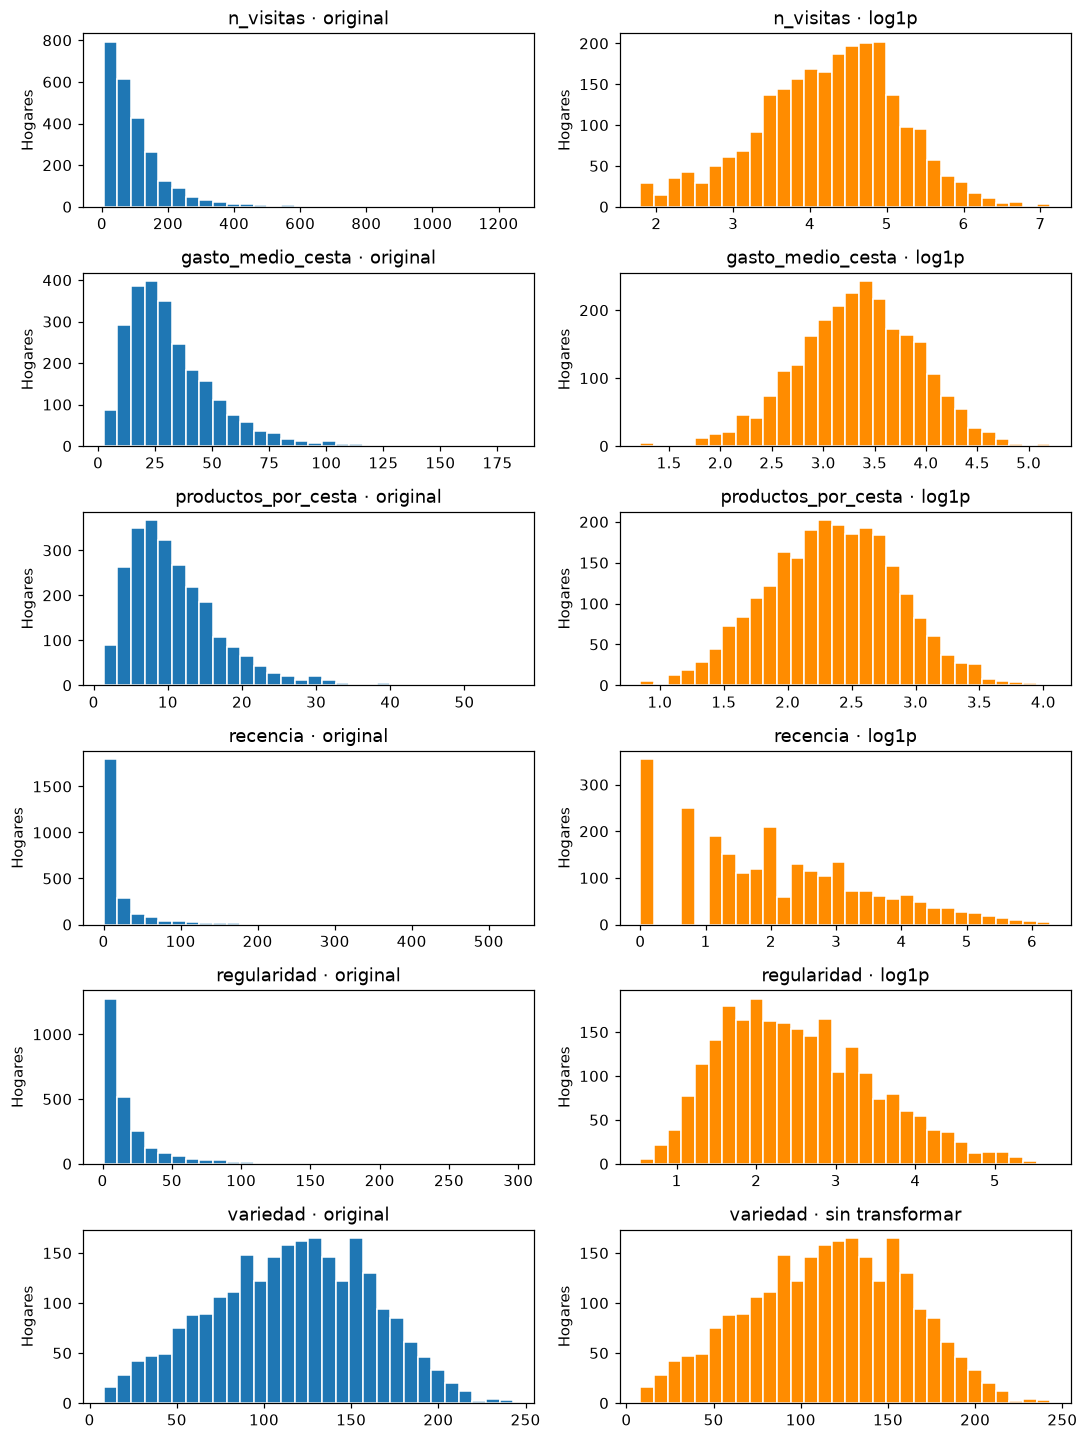

In [7]:
sin_escalar = hogares.copy()  # Conserva las unidades reales antes del logaritmo.
transformados = hogares.copy()
candidatas_log = ["n_visitas", "gasto_medio_cesta", "productos_por_cesta", "recencia", "regularidad", "variedad"]
columnas_log = [c for c in candidatas_log if hogares[c].skew() > 1]
for c in columnas_log:
    transformados[c] = np.log1p(transformados[c])

asimetria = pd.DataFrame({"antes": sin_escalar.skew(), "despues": transformados.skew()})
asimetria["log1p"] = asimetria.index.isin(columnas_log)
asimetria.to_csv(SALIDAS / "asimetria.csv", index_label="variable")
print("Variables con log1p:", columnas_log)
print(asimetria.round(3).to_string())

fig, ejes = plt.subplots(len(candidatas_log), 2, figsize=(10, 2.2 * len(candidatas_log)))
for fila, c in enumerate(candidatas_log):
    ejes[fila, 0].hist(sin_escalar[c], bins=30, edgecolor="white")
    ejes[fila, 0].set_title(c + " · original")
    ejes[fila, 1].hist(transformados[c], bins=30, edgecolor="white", color="darkorange")
    ejes[fila, 1].set_title(c + (" · log1p" if c in columnas_log else " · sin transformar"))
    for eje in ejes[fila]:
        eje.set_ylabel("Hogares")
plt.tight_layout()
plt.savefig(FIGURAS / "01_histogramas_transformaciones.png", dpi=160)
plt.show()

## 7. Redundancia (clase 4)
Se calcula la correlación de Pearson **después de las transformaciones y antes del escalado**.
Si dos variables superan |r| > 0,9, se conserva la primera en el orden acordado y se retira la posterior.
El criterio es sencillo y reproducible; la lista de pares y las columnas retiradas se guardan para justificar cualquier cambio.
La tabla en unidades reales tendrá las mismas columnas finales que la escalada.
**Resultado en el dataset completo:** se retiran `productos_por_cesta` (r=0,922 con `gasto_medio_cesta`)
y `regularidad` (r=-0,918 con `n_visitas`). Por tanto, se calculan las nueve variables acordadas,
pero quedan **siete entradas definitivas** al aplicar la regla de |r|>0,9 del propio plan.
Esto debe comunicarse al grupo antes de integrar la rama. La tabla completa de nueve variables en unidades reales
queda en `salidas/diagnostico/hogares_9_variables_sin_escalar.csv`, para que se pueda revisar la decisión sin recalcular.


Variables que se conservan: ['n_visitas', 'gasto_medio_cesta', 'recencia', 'variedad', 'pct_marca_propia', 'pct_fresco', 'pct_descuento']
Variables retiradas por redundancia: ['productos_por_cesta', 'regularidad']


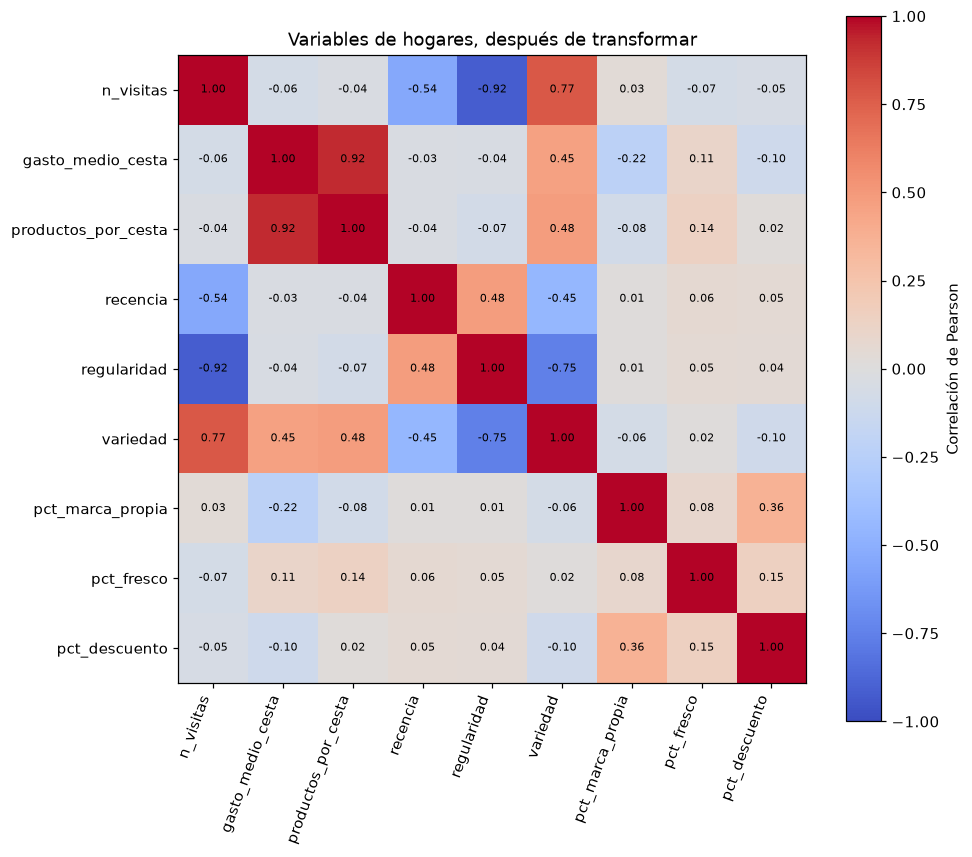

In [8]:
correlaciones = transformados.corr()
correlaciones.to_csv(SALIDAS / "correlaciones.csv", index_label="variable")
seleccionadas = []
retiradas = []
pares_redundantes = []
for c in variables:
    repetidas = [anterior for anterior in seleccionadas if abs(correlaciones.loc[c, anterior]) > 0.9]
    if repetidas:
        retiradas.append(c)
        for anterior in repetidas:
            pares_redundantes.append({"conservada": anterior, "retirada": c, "correlacion": correlaciones.loc[c, anterior]})
    else:
        seleccionadas.append(c)
print("Variables que se conservan:", seleccionadas)
print("Variables retiradas por redundancia:", retiradas)
pd.DataFrame(pares_redundantes, columns=["conservada", "retirada", "correlacion"]).to_csv(
    SALIDAS / "variables_redundantes.csv", index=False)

fig, eje = plt.subplots(figsize=(9, 8))
imagen = eje.imshow(correlaciones, vmin=-1, vmax=1, cmap="coolwarm")
eje.set_xticks(range(len(variables)), labels=variables, rotation=70, ha="right")
eje.set_yticks(range(len(variables)), labels=variables)
for i in range(len(variables)):
    for j in range(len(variables)):
        eje.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=eje, label="Correlación de Pearson")
eje.set_title("Variables de hogares, después de transformar")
plt.tight_layout()
plt.savefig(FIGURAS / "01_correlaciones.png", dpi=160)
plt.show()

## 8. Escalado y entrega definitiva (clase 4)
`StandardScaler` centra cada columna y la divide por su desviación típica. Así ni los dólares ni el número de visitas
imponen por sus unidades casi toda la distancia entre hogares.

Este es un análisis **descriptivo**, sin variable objetivo ni conjunto de test: el escalador se ajusta a los hogares
que se van a representar. Si más adelante se quisiera predecir sobre hogares nuevos, habría que separar los datos
antes de aprender medianas, transformaciones y escalado.

In [9]:
escalador = StandardScaler()
X = transformados[seleccionadas]
escalados = pd.DataFrame(escalador.fit_transform(X), index=X.index, columns=seleccionadas)
hogares_final = escalados.reset_index()
hogares_reales = sin_escalar[seleccionadas].reset_index()

# Comprobaciones del contrato antes de escribir los dos CSV.
assert hogares_final["household_key"].is_unique
assert hogares_final.columns.tolist() == hogares_reales.columns.tolist()
assert hogares_final["household_key"].equals(hogares_reales["household_key"])
assert np.isfinite(hogares_final[seleccionadas].to_numpy()).all()
assert np.isfinite(hogares_reales[seleccionadas].to_numpy()).all()
assert np.allclose(escalados.mean(), 0, atol=1e-10)
no_constantes = X.std(ddof=0).gt(0)
assert np.allclose(escalados.loc[:, no_constantes].std(ddof=0), 1, atol=1e-10)

# Se conserva además la tabla de nueve variables para revisar los descartes, sin usarla como entrada definitiva.
(SALIDAS / "diagnostico").mkdir(exist_ok=True)
sin_escalar.reset_index().to_csv(SALIDAS / "diagnostico" / "hogares_9_variables_sin_escalar.csv", index=False)

hogares_final.to_csv(SALIDAS / "hogares.csv", index=False)
hogares_reales.to_csv(SALIDAS / "hogares_sin_escalar.csv", index=False)
print("Entrega definitiva:", hogares_final.shape[0], "hogares y", len(seleccionadas), "variables")
print("Hogares y columnas de ambos archivos: coinciden")
print("Medias tras escalar:", escalados.mean().round(10).to_dict())
print("Desviaciones tras escalar:", escalados.std(ddof=0).round(6).to_dict())

Entrega definitiva: 2475 hogares y 7 variables
Hogares y columnas de ambos archivos: coinciden
Medias tras escalar: {'n_visitas': 0.0, 'gasto_medio_cesta': 0.0, 'recencia': -0.0, 'variedad': -0.0, 'pct_marca_propia': -0.0, 'pct_fresco': -0.0, 'pct_descuento': -0.0}
Desviaciones tras escalar: {'n_visitas': 1.0, 'gasto_medio_cesta': 1.0, 'recencia': 1.0, 'variedad': 1.0, 'pct_marca_propia': 1.0, 'pct_fresco': 1.0, 'pct_descuento': 1.0}


## 9. Registro de decisiones y procedencia
El registro permite ver con qué archivos y decisiones se han generado las tablas, sin subir los originales a Git.
Las proporciones de marca propia y fresco se expresan entre 0 y 1. `pct_descuento` es descuento de tienda/gasto neto:
no se recorta a 1 si en un hogar los descuentos superan el gasto neto.

El fichero en unidades reales permite describir los grupos sin interpretar logaritmos o desviaciones típicas.
La semilla 42 se usará en los métodos posteriores; esta agregación no genera números aleatorios.

In [10]:
procedencia_local = DATOS / "procedencia.json"
fuente = json.loads(procedencia_local.read_text(encoding="utf-8")) if procedencia_local.exists() else {}
registro = {
    "etapa": "definitiva",
    "fuente": fuente.get("fuente", "CSV locales de The Complete Journey"),
    "url_fuente": "https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey",
    "archivos_entrada": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [ruta_transacciones, ruta_productos]},
    "resumen": {k: int(v) if isinstance(v, (np.integer, int)) else float(v) for k, v in resumen.items()},
    "categorias_producto_desconocidas": blancos_producto,
    "minimo_cestas": 5,
    "regularidad": "Desviación muestral (ddof=1) de intervalos entre cestas ordenadas por DAY; se incluyen ceros del mismo día",
    "frescos": frescos,
    "columnas_log1p": columnas_log,
    "medianas_si_hay_ausencia": medianas.to_dict(),
    "valores_imputados": {c: int(v) for c, v in faltantes.items()},
    "variables_candidatas": variables,
    "variables_definitivas": seleccionadas,
    "retiradas_correlacion_mayor_0_9": retiradas,
    "unidades_proporciones": "pct_marca_propia y pct_fresco: 0-1; pct_descuento: razón descuento/gasto neto",
    "escalado": {c: {"media": float(m), "escala": float(s)} for c, m, s in zip(seleccionadas, escalador.mean_, escalador.scale_)},
    "semilla_comun": SEED,
    "versiones": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
(SALIDAS / "preprocesado_datos.json").write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
print("Decisiones guardadas en salidas/preprocesado_datos.json")

Decisiones guardadas en salidas/preprocesado_datos.json


## 10. Qué entrego y cómo explicarlo
- La versión rápida permite preparar el código de los demás mientras se termina la definitiva.
- La definitiva utiliza las nueve variables acordadas, salvo las retiradas por redundancia si las hubiera.
- Las categorías desconocidas se identifican, no se atribuyen a un departamento inventado.
- El filtro de visitas se calcula después de quitar `KIOSK-GAS`: por eso puede diferir del recuento inicial del plan.
- Eliminar pocas compras y comprimir valores extremos son decisiones distintas: una retira información escasa y la otra cambia la escala sin borrar hogares.
- Las variables de cupones y la demografía no se usan para construir los perfiles.
  Se reservan para que Óscar compruebe después si los grupos muestran diferencias.
- Un cruce con cupones del mismo periodo muestra asociación: por sí solo no demuestra causalidad ni garantiza una predicción futura.
- Los pasos de Métodos y Segmentos siguen correspondiendo a los otros dos notebooks del grupo.

Antes de entregar en grupo: integrar esta rama en `main` mediante revisión y ejecutar `01 → 02 → 03` en orden.
Este notebook no modifica `02_metodos.ipynb` ni `03_segmentos.ipynb`.
### Resultado de esta ejecución con los datos completos
- 2.595.732 líneas originales y 2.500 hogares.
- Se excluyen 22.059 líneas de gasolinera, que suman 544.222,28 dólares.
- La versión rápida tiene 2.500 hogares y cinco variables.
- La definitiva retiene 2.475 hogares; se excluyen 25 con menos de cinco cestas después de quitar gasolina.
  El plan menciona 23 antes de aplicar esta exclusión de compras.
- `regularidad` tiene nueve ausencias antes del filtro; después del filtro no queda ninguna y no se ha imputado ningún valor.
- Se aplica `log1p` a visitas, gasto medio, productos por cesta, recencia y regularidad.
- Se conservan siete variables tras retirar los dos pares redundantes. Se entrega la lista de columnas exacta en el registro JSON.
- Los dos CSV definitivos coinciden en filas, orden y nombres de columnas. No contienen valores infinitos ni ausentes.
